In [1]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
y_test = pd.read_csv('y_test_binary_sel.csv')
y_pred = pd.read_csv('Grok_Binary_Predictions.csv')
y_pred = y_pred.drop('sn', axis=1)

In [3]:
evaluation = pd.DataFrame([{
    'Model': 'Grok-4.5',
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-score': f1_score(y_test, y_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_pred)
}])

print(evaluation)

      Model  Accuracy  Precision    Recall  F1-score   ROC-AUC
0  Grok-4.5   0.88255   0.904762  0.926829  0.915663  0.855888


In [4]:
evaluation.to_csv('evaluation_grok_sel_binary.csv', index=False)

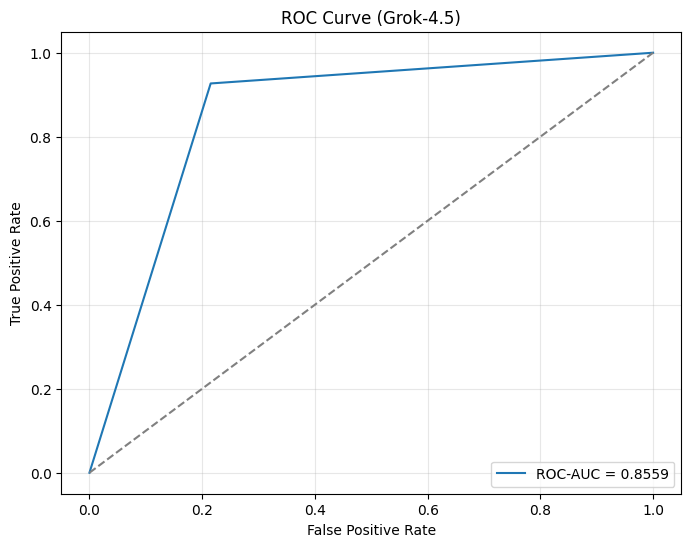

In [5]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.4f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Grok-4.5)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.show()

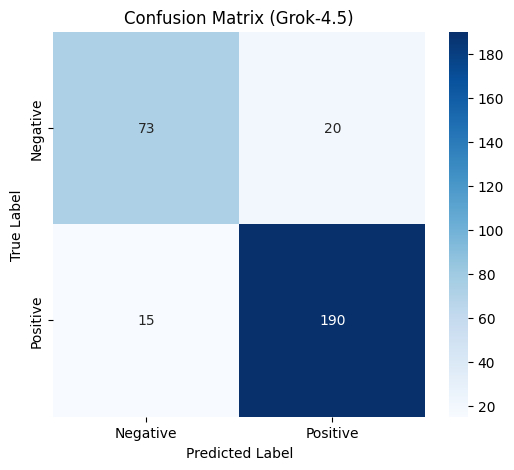

In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Grok-4.5)')
plt.show()